# Atividade Prática 3 — 01 · Etapa 1: meta-dados de desempenho

**IN1097 · Tópicos Avançados em Agentes Inteligentes 2** — Johnattan D. F. Viana

A atividade está dividida em quatro notebooks, um por etapa; cada um grava o que o próximo lê, então dá para abrir e avaliar
qualquer etapa sem rodar as anteriores de novo:

| Notebook | Etapa | Lê | Grava |
|---|---|---|---|
| `01_Etapa1-MetaDados.ipynb` | Etapa 1: meta-dados de desempenho (matriz de perdas K × n) | `data/` | `results/matriz_de_perdas.csv`, `results/configuracoes.csv` |
| `02_MetaCaracteristicas-OurTrained.ipynb` | meta-características; treino da **Our-Trained** (1024 dims) | `data/`, `representations/` | `representations/Our-Trained_split{k}.csv`, `results/models/` |
| `03_Etapa2-Buscas.ipynb` | Etapa 2: **roda e salva** as buscas (métodos 1–5) | `data/`, `representations/` | `results/curvas/*.npz` |
| `04_Analises.ipynb` | Seção 2.1: Análises 1, 2 e 3 (**só lê** os resultados; não roda busca nem treino) | `results/curvas/`, `representations/` | `results/tables/`, `results/figures/` |

**Problema.** Trocamos o problema das Atividades 1 e 2 pela meta-task de *warm-start* de HPO do paper do Dataset2Vec
(Jomaa, Schmidt-Thieme & Grabocka, 2021, seção 6.3): **120 datasets de classificação do UCI** (a mesma coleção pré-processada
de Fernández-Delgado et al. de onde vieram os 30 datasets da Atividade 1) × **3456 configurações de uma rede feed-forward**.
A pergunta deixa de ser *qual algoritmo* e passa a ser *com qual configuração começar a busca* da rede.

In [1]:
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "src" / "config.py").exists():
    ROOT = Path(r"D:\Projetos\DisciplinaMtL\entrega3")
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as cfg, search, analysis as an
from src.metatask_data import load_meta_task

an.setup_matplotlib()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
cfg.make_dirs()

def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(cfg.FIGURES_DIR / f"{name}.{ext}", bbox_inches="tight", facecolor="white")

def save_table(df, name, index=True):
    df.to_csv(cfg.TABLES_DIR / f"{name}.csv", index=index)

from src import metatask_data as md

## Dados

`data/` já vem com a meta-task (respostas das 3456 configurações nos 120 datasets, grid, splits do D2V e datasets brutos). A
célula abaixo só baixa do servidor do ISMLL (~1 GB) se algo estiver faltando. **Atenção:** cada zip traz o grid em uma ordem
diferente; o carregador canoniza a ordem para que o `config_id` designe a mesma configuração em todos os datasets (requisito para
transferir configurações de um dataset para outro) e descarta linhas repetidas da mesma configuração (ex.: `acute-inflammation`).

In [2]:
if not (md.meta_task_is_downloaded() and md.reference_metafeatures_are_downloaded()):
    print("Baixando a meta-task (falta algo em data/)...")
    print(md.download_all())
meta = load_meta_task()
print(f"{meta.n_ds} datasets | {meta.n_cfg} configurações por dataset | {cfg.N_SPLITS} splits")

120 datasets | 3456 configurações por dataset | 5 splits


## Algoritmo, espaço Θ e as K configurações

**Algoritmo base:** rede neural feed-forward (MLP, 50 épocas). É o algoritmo da meta-task do Dataset2Vec, a tarefa em que
avaliamos representações de datasets na pesquisa; e o MLP era um dos candidatos da Atividade 2.

**Espaço Θ** (7 hiperparâmetros): ativação · forma da arquitetura · dropout · nº de camadas · neurônios · batch-norm · otimizador.
**K = 3456** (grid completo; com 1 camada só existe a forma SQU, por isso não são 4320). **Por que grade:** o meta-dataset é um
fatorial completo — a matriz K × n fica completa e sem imputação, o que permite simular as buscas e conhecer L\* exatamente.

**Configuração padrão:** o ponto do grid mais próximo do default do `MLPClassifier` do scikit-learn (1 camada de 100 neurônios,
ReLU, Adam, sem dropout/batch-norm) → ReLU, SQU, dropout 0, **1 camada de 32 neurônios** (a maior largura do grid), sem
batch-norm, Adam.

**Protocolo de validação:** o mesmo para as K × n células — cada configuração é treinada por 50 épocas na partição de treino de
cada dataset e avaliada na partição de validação (hold-out fixo do meta-dataset). **Perda = 1 − acurácia de validação na época
50.** (A acurácia de teste existe no meta-dataset, mas não é usada pelas buscas.)

In [3]:
L = search.loss_matrix(meta)                         # (n_ds x K)
K, n = meta.n_cfg, meta.n_ds
default_idx = search.default_config_index(meta.configs)

# Matriz de perdas K x n (uma linha por configuração, uma coluna por dataset) — o meta-conhecimento desta atividade
loss_df = pd.DataFrame(L.T, index=pd.RangeIndex(K, name="config_id"), columns=meta.names)
loss_df.round(4).to_csv(cfg.LOSS_MATRIX_CSV)
configs = meta.configs.copy(); configs.index.name = "config_id"
configs["padrao"] = configs.index == default_idx
configs.to_csv(cfg.CONFIGS_CSV)
print(f"Matriz de perdas: {loss_df.shape[0]} configurações x {loss_df.shape[1]} datasets -> {cfg.LOSS_MATRIX_CSV.relative_to(ROOT)}")
print(f"Configuração padrão = config_id {default_idx}: {meta.configs.iloc[default_idx].to_dict()}")
display(pd.DataFrame({c: [", ".join(map(str, sorted(meta.configs[c].unique()))), meta.configs[c].nunique()]
                      for c in cfg.CONFIG_COLS}, index=["valores", "nº"]).T)
display(loss_df.iloc[:5, :6].round(4))

Matriz de perdas: 3456 configurações x 120 datasets -> results\matriz_de_perdas.csv
Configuração padrão = config_id 1818: {'ACTIVATION': 'relu', 'ARCHITECTURE': 'SQU', 'DROPOUT': 0.0, 'LAYERS': 1, 'NEURONS': 32, 'NORMALIZATION': 0, 'OPTIMZERS': 'adam'}


,valores,nº
ACTIVATION,"leaky_relu, relu, selu",3
ARCHITECTURE,"ASC, DES, ENC, SQU, SYM",5
DROPOUT,"0.0, 0.2, 0.5",3
LAYERS,"1, 3, 5, 7",4
NEURONS,"4, 8, 16, 32",4
NORMALIZATION,"0, 1",2
OPTIMZERS,"adam, rmsprop, sgd",3


,abalone,acute-inflammation,acute-nephritis,adult,annealing,arrhythmia
config_id,,,,,,
0,0.3606,0.000,0.0000,0.1544,0.1420,0.5125
1,0.3638,0.000,0.0000,0.1562,0.1420,0.4875
2,0.4071,0.875,0.4375,0.1627,0.2557,0.4250
3,0.3718,0.000,0.0000,0.1556,0.1193,0.3500
4,0.3670,0.000,0.0000,0.1611,0.1534,0.4000


## Os datasets e a matriz de perdas

In [4]:
ds_info = an.dataset_table(meta, L, default_idx)
save_table(ds_info, "datasets_resumo")
display(ds_info.describe().T.round(3))
print(f"Em {int((ds_info['frac. configs no ótimo'] >= 0.01).sum())} datasets >= 1% das K configurações empatam no ótimo; "
      f"mediana de {int(ds_info['valores distintos de perda'].median())} valores distintos de perda por dataset "
      f"(partições de validação pequenas).")

,count,mean,std,min,25%,50%,75%,max
n_instancias,120.0,4592.375,15110.376,16.000,209.500,686.500,2144.750,130064.000
n_features,120.0,28.842,40.965,3.000,8.000,16.000,33.000,262.000
n_classes,120.0,6.892,15.526,2.000,2.000,3.000,6.000,100.000
L*,120.0,0.098,0.111,0.000,0.004,0.057,0.154,0.438
L pior,120.0,0.758,0.220,0.089,0.616,0.779,0.955,1.000
frac. configs no ótimo,120.0,0.027,0.105,0.000,0.000,0.001,0.003,0.709
valores distintos de perda,120.0,142.567,284.938,5.000,24.000,44.000,113.750,1870.000
perda norm. do padrão,120.0,0.170,0.164,0.000,0.044,0.117,0.233,0.681


Em 18 datasets >= 1% das K configurações empatam no ótimo; mediana de 44 valores distintos de perda por dataset (partições de validação pequenas).


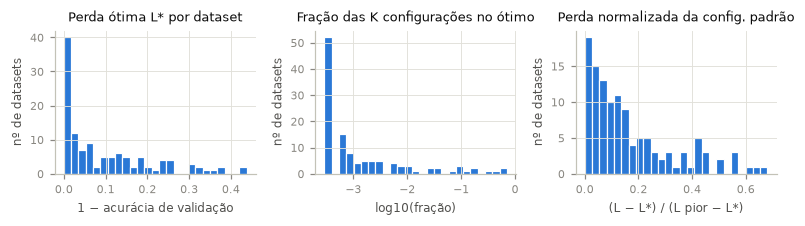

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.1))
for ax, col, title, xl in [
        (axes[0], ds_info["L*"], "Perda ótima L* por dataset", "1 − acurácia de validação"),
        (axes[1], np.log10(ds_info["frac. configs no ótimo"]), "Fração das K configurações no ótimo", "log10(fração)"),
        (axes[2], ds_info["perda norm. do padrão"], "Perda normalizada da config. padrão", "(L − L*) / (L pior − L*)")]:
    ax.hist(col, bins=25, color="#2a78d6", edgecolor="white", linewidth=0.8)
    ax.set(title=title, xlabel=xl, ylabel="nº de datasets")
fig.tight_layout(); save_fig(fig, "etapa1_meta_dados"); plt.show()

## Tamanho do conjunto e custo de construção

In [6]:
print(f"K = {K} >= 3T = {3 * cfg.T_BUDGET}: {'OK' if K >= 3 * cfg.T_BUDGET else 'NÃO'} (T = {cfg.T_BUDGET}, n_init = {cfg.N_INIT})")
print(f"Custo de construção: K x n x folds = {K} x {n} x 1 = {K * n:,} treinos de 50 épocas (um hold-out por dataset), "
      f"pré-computados pelos autores do meta-dataset (ISMLL). Nesta entrega o custo foi baixar ~1 GB e ler o cache.")
print(f"Com a matriz completa a busca é simulada: avaliar uma configuração = ler uma célula. Uma busca de T={cfg.T_BUDGET} "
      f"equivaleria a {cfg.T_BUDGET} treinos reais ({100 * cfg.T_BUDGET / K:.1f}% do grid).")

K = 3456 >= 3T = 300: OK (T = 100, n_init = 20)
Custo de construção: K x n x folds = 3456 x 120 x 1 = 414,720 treinos de 50 épocas (um hold-out por dataset), pré-computados pelos autores do meta-dataset (ISMLL). Nesta entrega o custo foi baixar ~1 GB e ler o cache.
Com a matriz completa a busca é simulada: avaliar uma configuração = ler uma célula. Uma busca de T=100 equivaleria a 100 treinos reais (2.9% do grid).
